In [7]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from econml.dml import CausalForestDML
import os

Seedn = 886
df = pd.read_csv(r'D:\Python39\Code-NG\data\Data_all.csv', encoding='utf-8-sig')
out_dir = r'D:\Python39\Code-NG\results'
# ===================== 【变量】 =====================
# GLAD 系列（因变量）
COL_Y = "mean_LSED"          # 核心GLAD因变量
# GLDAS 系列（处理变量+混杂变量）
COL_T = "ERA_TAS"          # 核心GLDAS温度（处理变量T）
COL_GLDAS_PER = "ERA_PER"  # GLDAS降水（混杂）
# 固定变量
COL_GRID = "Grid_Area"       # 栅格面积  Surface area of each grid
COL_M = "Pf_mean"            # 中介变量   Mean annual ground temperature
# 混杂变量列表
X_NUMERIC = ['ICE','oDEM','oStd', COL_GLDAS_PER,'EVI','Soil_sand','Soil_silt','Soil_SGU']  
#Ground ICE content, Elevation, terrain relief, Territerrestrial water balance(PER), EVI indice, Sand content ‰, Silt content Soil_SGU: GUM_sediment 
X_CATEGORY = ['LGM','peatlands','GLiM']# Last glacier maximum, Peatlands extent, Global Lithological Map
must_use_cols = [COL_Y, COL_T, COL_GLDAS_PER, COL_GRID, COL_M] + X_NUMERIC + X_CATEGORY

# ===================== 最大值归一化器 =====================
class ZeroPreservingScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        if len(X.shape) == 1:
            self.max_abs_ = np.max(np.abs(X))
        else:
            self.max_abs_ = np.max(np.abs(X), axis=0)
        self.max_abs_[self.max_abs_ == 0] = 1.0
        return self
    def transform(self, X):
        return X / self.max_abs_
    def inverse_transform(self, X):
        return X * self.max_abs_

# ===================== 1. 数据读取与筛选 =====================

data = df[(df[COL_M] < 0)].copy()
data = data.dropna(subset=must_use_cols)
print(f"筛选后数据量：{len(data)}")
data['Lake_density'] = data[COL_Y] / data[COL_GRID]
# ===================== 2. 变量归一化 =====================
scalers = {}

# Y = mean_GLAD / Grid_Area
y_raw = (data[COL_Y] / data[COL_GRID]).values.reshape(-1,1)
scalers['Y'] = ZeroPreservingScaler()
y_scaled = scalers['Y'].fit_transform(y_raw).flatten()

# T = GLDAS_TAS (处理变量)
T_tas_raw = data[COL_T].values.reshape(-1,1)
scalers['T_tas'] = ZeroPreservingScaler()
T_tas_scaled = scalers['T_tas'].fit_transform(T_tas_raw).flatten()

# M = Pf_mean (第二个处理变量)
pf_raw = data[COL_M].values.reshape(-1,1)
scalers['T_pf_M'] = ZeroPreservingScaler()
M_scaled = scalers['T_pf_M'].fit_transform(pf_raw).flatten()

# 混淆变量预处理
X_base = data[X_NUMERIC+X_CATEGORY].copy()
preprocessor = ColumnTransformer(
    transformers=[('num', ZeroPreservingScaler(), X_NUMERIC)],
    remainder='passthrough'
)
W_processed = preprocessor.fit_transform(X_base)

# ===================== 缩放系数校验 =====================
print("\n===== 归一化缩放系数校验 =====")
print(f"Y_max_abs (Y) = {scalers['Y'].max_abs_[0]:.4f}")
print(f"T_tas_max_abs (T=ERA_TAS) = {scalers['T_tas'].max_abs_[0]:.4f}")
print(f"T_pf_max_abs (T=Pf_mean) = {scalers['T_pf_M'].max_abs_[0]:.4f}")
print(f"反归一化系数 TAS→Y: {scalers['Y'].max_abs_[0]/scalers['T_tas'].max_abs_[0]:.4f}")
print(f"反归一化系数 Pf→Y:  {scalers['Y'].max_abs_[0]/scalers['T_pf_M'].max_abs_[0]:.4f}")

# ===================== 3. 因果模型 =====================
def train_causal_model(X, T, y):
    model = CausalForestDML(
        model_y=RandomForestRegressor(n_estimators=100, random_state=Seedn, n_jobs=-1),
        model_t=RandomForestRegressor(n_estimators=100, random_state=Seedn, n_jobs=-1),
        n_estimators=100, max_depth=5, min_samples_leaf=20, random_state=Seedn
    )
    model.fit(X=X, T=T, Y=y)
    ite = model.effect(X).flatten()
    lo, hi = model.effect_interval(X, alpha=0.05)
    return ite, lo.flatten(), hi.flatten()

print("\n计算效应...")
# 效应1：Total_ITE，T=ERA_TAS，混杂变量W
total_ite, total_lo, total_hi = train_causal_model(W_processed, T_tas_scaled, y_scaled)
# 效应2：Media_ITE，T替换为中介变量Pf_mean，同样混杂变量W
media_ite, media_lo, media_hi = train_causal_model(W_processed, M_scaled, y_scaled)

# ===================== 4. 反归一化 =====================
coef_tas = scalers['Y'].max_abs_[0] / scalers['T_tas'].max_abs_[0]
coef_pf  = scalers['Y'].max_abs_[0] / scalers['T_pf_M'].max_abs_[0]
grid_area = data[COL_GRID].values

# 还原原始单位
total_ite, total_lo, total_hi = total_ite*coef_tas*grid_area, total_lo*coef_tas*grid_area, total_hi*coef_tas*grid_area
media_ite, media_lo, media_hi = media_ite*coef_pf*grid_area, media_lo*coef_pf*grid_area, media_hi*coef_pf*grid_area

# ===================== 5. ✅ 精简输出 =====================

os.makedirs(out_dir, exist_ok=True)

# 只保留两个效应：Total_ITE（ERA_TAS效应）、Media_ITE（Pf_mean效应）
result_df = pd.DataFrame({
    # 两组因果效应 + 95%置信区间
    'Total_ITE': total_ite, 'Total_lower': total_lo, 'Total_upper': total_hi,
    'Media_ITE': media_ite, 'Media_lower': media_lo, 'Media_upper': media_hi,

    # 原始核心变量 + Lake_density（完全保留原有变量）
    'ICE': data['ICE'], 'oDEM': data['oDEM'], 'oStd': data['oStd'],
    'Grid_Area': data['Grid_Area'], 'Lake_density': data['Lake_density'],
    'Pf_mean': data['Pf_mean'], 'LGM': data['LGM'], 'peatlands': data['peatlands'],
    'Soil_sand': data['Soil_sand'], 'Soil_silt': data['Soil_silt'], 'Soil_SGU': data['Soil_SGU'],
    'GLiM': data['GLiM'], 'Basin': data['Basin'],
    'GLDAS_TAS': data['GLDAS_TAS'],'ERA_TAS': data['ERA_TAS'],
    '.geo': data['.geo'],
})

# 保存结果，文件名维持不变
result_df.to_csv(os.path.join(out_dir, 'ITE_LSED_ERA.csv'), index=False, encoding='utf-8-sig')

# ===================== 结果打印 =====================
print("\n===== 反归一化后效应范围 =====")
print(f"Total_ITE (ERA_TAS):   [{total_ite.min():.4f}, {total_ite.max():.4f}]")
print(f"Media_ITE (Pf_mean):   [{media_ite.min():.4f}, {media_ite.max():.4f}]")
print(f"\n✅ 文件已保存：{out_dir}\\ITE_LSED_ERA.csv")

筛选后数据量：83226

===== 归一化缩放系数校验 =====
Y_max_abs (Y) = 1.0049
T_tas_max_abs (T=ERA_TAS) = 15.3948
T_pf_max_abs (T=Pf_mean) = 10.8490
反归一化系数 TAS→Y: 0.0653
反归一化系数 Pf→Y:  0.0926

计算效应...

===== 反归一化后效应范围 =====
Total_ITE (ERA_TAS):   [-1.0946, 2.2688]
Media_ITE (Pf_mean):   [-0.8429, 2.4574]

✅ 文件已保存：D:\Python39\Code-NG\results\ITE_LSED_ERA.csv


In [8]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from econml.dml import CausalForestDML
import os

Seedn = 886
df = pd.read_csv(r'D:\Python39\Code-NG\data\Data_all.csv', encoding='utf-8-sig')
out_dir = r'D:\Python39\Code-NG\results'
# ===================== 【变量重定义】 =====================
# 被解释变量：二值化drainage_flag（1/2=1，其他=0）二元结局
COL_Y_RAW = "drainage_flag"
# 处理变量1：核心温度自变量
COL_T = "ERA_TAS"
# 处理变量2：Pf_mean单独作为自变量估计对排水概率的效应
COL_M = "Pf_mean"
# 降水混杂变量
COL_GLDAS_PER = "ERA_PER"
# 辅助字段
COL_GRID = "Grid_Area"

# 混杂变量（保留ERA_PER_slope，和之前一致）
X_NUMERIC = ['ICE','oDEM','oStd', COL_GLDAS_PER,'EVI','Soil_sand','Soil_silt','Soil_SGU','ERA_PER_slope'] 
X_CATEGORY = ['LGM','peatlands','GLiM']

core_must_cols = [COL_Y_RAW, COL_T, COL_GLDAS_PER, COL_GRID, COL_M]
all_covar_cols = X_NUMERIC + X_CATEGORY

# ===================== 最大值保留归一化器 =====================
class ZeroPreservingScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        if len(X.shape) == 1:
            self.max_abs_ = np.max(np.abs(X))
        else:
            self.max_abs_ = np.max(np.abs(X), axis=0)
        self.max_abs_[self.max_abs_ == 0] = 1.0
        return self
    def transform(self, X):
        return X / self.max_abs_
    def inverse_transform(self, X):
        return X * self.max_abs_

# ===================== 统一二元分类因果森林训练函数 =====================
def train_binary_causal(X, T, y):
    # 二元离散结局，Y为0/1排水标签
    model = CausalForestDML(
        model_y=RandomForestClassifier(n_estimators=100, random_state=Seedn, n_jobs=-1),
        model_t=RandomForestRegressor(n_estimators=100, random_state=Seedn, n_jobs=-1),
        n_estimators=100, max_depth=5, min_samples_leaf=20,
        discrete_outcome=True,
        random_state=Seedn
    )
    model.fit(X=X, T=T, Y=y)
    ite = model.effect(X).flatten()
    ci_low, ci_high = model.effect_interval(X, alpha=0.05)
    return ite, ci_low.flatten(), ci_high.flatten()

# ===================== 1. 数据读取、筛选、缺失填充、标签二值化 =====================

print(f"原始总条数：{len(df):,}")

# 筛选Pf_mean < 0
data = df[(df[COL_M] < 0)].copy()

# 仅核心因果字段删缺失
data = data.dropna(subset=core_must_cols)

# 数值协变量中位数填充，分类协变量众数填充
for col in X_NUMERIC:
    data[col] = data[col].fillna(data[col].median())
for col in X_CATEGORY:
    data[col] = data[col].fillna(data[col].mode()[0])

print(f"筛选+缺失填充后最终样本量：{len(data):,}")

# 构建二元因变量：drainage_flag=1或2 → 1（发生排水），其余0
data['Y_binary'] = np.where(data[COL_Y_RAW].isin([1, 2,3]), 1, 0)
y_binary = data['Y_binary'].values
data['Lake_density'] = data['mean_LSED'] / data['Grid_Area']
# ===================== 2. 自变量归一化缩放 =====================
scalers = {}

# 温度T缩放
T_tas_raw = data[COL_T].values.reshape(-1, 1)
scalers['T_tas'] = ZeroPreservingScaler()
T_tas_scaled = scalers['T_tas'].fit_transform(T_tas_raw).flatten()

# Pf_mean缩放（第二个Treatment）
pf_raw = data[COL_M].values.reshape(-1, 1)
scalers['T_pf_M'] = ZeroPreservingScaler()
M_scaled = scalers['T_pf_M'].fit_transform(pf_raw).flatten()

# 混杂变量预处理流水线
X_base = data[X_NUMERIC + X_CATEGORY].copy()
preprocessor = ColumnTransformer(
    transformers=[('num', ZeroPreservingScaler(), X_NUMERIC)],
    remainder='passthrough'
)
W_processed = preprocessor.fit_transform(X_base)

# ===================== 3. 两套独立DML模型计算效应 =====================
print("\n开始计算二元排水事件两套因果边际概率效应...")
# 模型1：气温对排水发生概率总效应
temp_total_ite, temp_total_lo, temp_total_hi = train_binary_causal(W_processed, T_tas_scaled, y_binary)
# 模型2：Pf_mean单独对排水发生概率效应
pf_mediator_ite, pf_mediator_lo, pf_mediator_hi = train_binary_causal(W_processed, M_scaled, y_binary)

# 说明：二元概率效应无面积单位，不需要反归一化还原

# ===================== 4. 结果组装并导出 =====================
os.makedirs(out_dir, exist_ok=True)

result_df = pd.DataFrame({
    # 气温总效应 + 95%置信区间
    'Total_ITE': temp_total_ite,
    'Total_lower': temp_total_lo,
    'Total_upper': temp_total_hi,

    # Pf_mean单独中介效应 + 95%置信区间
    'Media_ITE': pf_mediator_ite,
    'Media_lower': pf_mediator_lo,
    'Media_upper': pf_mediator_hi,

    # 原始保留字段
    'ICE': data['ICE'], 'oDEM': data['oDEM'], 'oStd': data['oStd'],
    'Grid_Area': data['Grid_Area'],'Lake_density': data['Lake_density'],
    'Pf_mean': data['Pf_mean'], 'LGM': data['LGM'], 'peatlands': data['peatlands'],
    'Soil_sand': data['Soil_sand'], 'Soil_silt': data['Soil_silt'], 'Soil_SGU': data['Soil_SGU'],
    'GLiM': data['GLiM'], 'Basin': data['Basin'],
    'ERA_PER_slope': data['ERA_PER_slope'],
    'ERA_PER': data['ERA_PER'],
    'ERA_TAS': data['ERA_TAS'],
    'raw_drainage_flag': data['drainage_flag'],
    'Y_binary_drainage': data['Y_binary'],
    '.geo': data['.geo']
})

save_filename = "ITE_Drainage_LSED_ERA.csv"
save_full_path = os.path.join(out_dir, save_filename)
result_df.to_csv(save_full_path, index=False, encoding='utf-8-sig')

# ===================== 5. 终端打印汇总 =====================
print("\n===== 二元排水事件边际概率效应取值范围 =====")
print(f"气温总效应 Temp_Total_ITE:      [{temp_total_ite.min():.4f}, {temp_total_ite.max():.4f}]")
print(f"Pf单独效应 Pf_Mediator_ITE:    [{pf_mediator_ite.min():.4f}, {pf_mediator_ite.max():.4f}]")
print(f"\n✅ 结果文件已保存：{save_full_path}")
print("字段释义：")
print("1. Temp_Total_ITE：气温升高1单位，湖泊发生排水事件概率变化量")
print("2. Pf_Mediator_ITE：Pf_mean每变化1单位，湖泊发生排水事件概率变化量")
print("3. 后缀lower/upper为95%置信区间上下限")

原始总条数：83,226
筛选+缺失填充后最终样本量：83,226

开始计算二元排水事件两套因果边际概率效应...

===== 二元排水事件边际概率效应取值范围 =====
气温总效应 Temp_Total_ITE:      [-0.3317, 0.2337]
Pf单独效应 Pf_Mediator_ITE:    [-0.1959, 0.1377]

✅ 结果文件已保存：D:\Python39\Code-NG\results\ITE_Drainage_LSED_ERA.csv
字段释义：
1. Temp_Total_ITE：气温升高1单位，湖泊发生排水事件概率变化量
2. Pf_Mediator_ITE：Pf_mean每变化1单位，湖泊发生排水事件概率变化量
3. 后缀lower/upper为95%置信区间上下限


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam, BSplines
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin

np.random.seed(666)
f_path=r'D:\Python39\Code-NG\data\Data_all.csv'
# ===================== 【核心配置：一键修改变量，完全统一】 =====================
# GLAD 系列（因变量）
COL_Y = "mean_LSED"          # 核心GLAD因变量
# GLDAS 系列（处理变量+混杂变量）
COL_T = "ERA_TAS"            # 核心处理变量T：ERA_TAS
COL_GLDAS_PER = "ERA_PER"    # 降水混杂变量
# 固定变量
COL_GRID = "Grid_Area"       # 栅格面积
COL_M = "Pf_mean"            # 中介变量M
# 混杂变量列表
X_NUMERIC = ['ICE','oDEM','oStd', COL_GLDAS_PER,'EVI','Soil_sand','Soil_silt','Soil_SGU']
X_CATEGORY = ['LGM','peatlands','GLiM']
must_use_cols = [COL_Y, COL_T, COL_GLDAS_PER, COL_GRID, COL_M] + X_NUMERIC + X_CATEGORY

# ===================== 最大值归一化器 =====================
class ZeroPreservingScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        if len(X.shape) == 1:
            self.max_abs_ = np.max(np.abs(X))
        else:
            self.max_abs_ = np.max(np.abs(X), axis=0)
        self.max_abs_[self.max_abs_ == 0] = 1.0
        return self
    def transform(self, X):
        return X / self.max_abs_
    def inverse_transform(self, X):
        return X * self.max_abs_

# --------------------------
# 数据准备
# --------------------------
def prepare_data(file_path):
    """数据读取、筛选、归一化预处理"""
    df = pd.read_csv(file_path, encoding='utf-8-sig')
    # 数据筛选
    data = df[(df[COL_M] < 0)].copy()
    data = data.dropna(subset=must_use_cols)
    print(f"筛选后有效数据量：{len(data)}")

    scalers = {}
    # 1. 因变量 Y 归一化
    y_raw = (data[COL_Y] / data[COL_GRID]).values.reshape(-1, 1)
    scalers['Y'] = ZeroPreservingScaler()
    y_scaled = scalers['Y'].fit_transform(y_raw).flatten()

    # 2. 处理变量 T 归一化
    T_raw = data[COL_T].values.reshape(-1, 1)
    scalers['T'] = ZeroPreservingScaler()
    T_scaled = scalers['T'].fit_transform(T_raw).flatten()

    # 3. 中介变量 M 归一化
    M_raw = data[COL_M].values.reshape(-1, 1)
    scalers['M'] = ZeroPreservingScaler()
    M_scaled = scalers['M'].fit_transform(M_raw).flatten()

    # 4. 混淆变量预处理（数值归一化，分类变量保留）
    X_base = data[X_NUMERIC + X_CATEGORY].copy()
    preprocessor = ColumnTransformer(
        transformers=[('num', ZeroPreservingScaler(), X_NUMERIC)],
        remainder='passthrough'
    )
    W_processed = preprocessor.fit_transform(X_base)

    # 安全边界（用于GAM样条，避免越界）
    T_min, T_max = T_scaled.min(), T_scaled.max()
    T_safe_min, T_safe_max = T_min - 0.2*(T_max-T_min), T_max + 0.2*(T_max-T_min)
    M_min, M_max = M_scaled.min(), M_scaled.max()
    M_safe_min, M_safe_max = M_min - 0.2*(M_max-M_min), M_max + 0.2*(M_max-M_min)

    return {
        'X': W_processed, 'T': T_scaled, 'y': y_scaled, 'M': M_scaled,
        'T_safe_min': T_safe_min, 'T_safe_max': T_safe_max,
        'M_safe_min': M_safe_min, 'M_safe_max': M_safe_max,
        'scalers': scalers,
        'n_samples': len(data)
    }

# --------------------------
# GAM模型中介分析
# --------------------------
def gam_mediation_analysis(data_dict, n_boot=500):
    X, T, y, M = data_dict['X'], data_dict['T'], data_dict['y'], data_dict['M']
    T_safe_min, T_safe_max = data_dict['T_safe_min'], data_dict['T_safe_max']
    n_samples = data_dict['n_samples']
    
    print("\n===== GAM模型中介分析 =====")
    # 1. T→M 线性回归
    model_m = sm.OLS(M, sm.add_constant(T)).fit()
    print(f"TAS→Pf 系数: {model_m.params[1]:.3f}, p值: {model_m.pvalues[1]:.3f}, R²: {model_m.rsquared:.3f}")

    # 微小扰动计算边际效应
    T_std = np.std(T)
    delta_T = 1e-9 * T_std
    
    # Bootstrap置信区间
    def gam_bootstrap():
        boot_te, boot_de, boot_ie = [], [], []
        for i in range(n_boot):
            if (i+1) % 100 == 0:
                print(f"GAM Bootstrap进度: {i+1}/{n_boot}")
                
            idx = np.random.choice(n_samples, n_samples, replace=True)
            T_b, M_b, y_b, X_b = T[idx], M[idx], y[idx], X[idx]
            
            T_b_extended = np.concatenate([[T_safe_min], T_b, [T_safe_max]])
            y_b_extended = np.concatenate([[y_b[0]], y_b, [y_b[-1]]])
            
            # 总效应模型：Y ~ s(T) + X
            splines_total_b = BSplines(T_b_extended, df=4, degree=3)
            X_total_b = sm.add_constant(X_b)
            model_total_b = GLMGam(y_b_extended, np.vstack([X_total_b[0], X_total_b, X_total_b[-1]]), 
                                  smoother=splines_total_b).fit(disp=False)
            
            # 直接效应模型：Y ~ s(T) + M + X
            splines_t_b = BSplines(T_b_extended, df=4, degree=3)
            X_gam_direct_b = sm.add_constant(np.column_stack([M_b, X_b]))
            model_direct_b = GLMGam(y_b_extended, np.vstack([X_gam_direct_b[0], X_gam_direct_b, X_gam_direct_b[-1]]), 
                                   smoother=splines_t_b).fit(disp=False)
            
            T_b_plus = np.clip(T_b + delta_T, T_safe_min, T_safe_max)
            pred_orig = model_total_b.predict(X_total_b, exog_smooth=T_b)
            pred_t1 = model_total_b.predict(X_total_b, exog_smooth=T_b_plus)
            te = np.mean(pred_t1 - pred_orig) / delta_T
            
            pred_d_orig = model_direct_b.predict(X_gam_direct_b, exog_smooth=T_b)
            pred_d_t1 = model_direct_b.predict(X_gam_direct_b, exog_smooth=T_b_plus)
            de = np.mean(pred_d_t1 - pred_d_orig) / delta_T
            
            boot_te.append(te)
            boot_de.append(de)
            boot_ie.append(te - de)
        
        return {
            '总效应': (np.mean(boot_te), np.percentile(boot_te, 2.5), np.percentile(boot_te, 97.5)),
            '直接效应': (np.mean(boot_de), np.percentile(boot_de, 2.5), np.percentile(boot_de, 97.5)),
            '间接效应': (np.mean(boot_ie), np.percentile(boot_ie, 2.5), np.percentile(boot_ie, 97.5))
        }
    
    gam_results = gam_bootstrap()
    print(f"\n效应分解结果：")
    print(f"总效应 (TAS→Y): {gam_results['总效应'][0]:.3f} (95% CI: [{gam_results['总效应'][1]:.3f}, {gam_results['总效应'][2]:.3f}])")
    print(f"直接效应 (TAS→Y|Pf): {gam_results['直接效应'][0]:.3f} (95% CI: [{gam_results['直接效应'][1]:.3f}, {gam_results['直接效应'][2]:.3f}])")
    print(f"间接效应 (TAS→Pf→Y): {gam_results['间接效应'][0]:.3f} (95% CI: [{gam_results['间接效应'][1]:.3f}, {gam_results['间接效应'][2]:.3f}])")
    
    return gam_results

# --------------------------
# 主函数
# --------------------------
if __name__ == "__main__":
    plt.rcParams["font.family"] = ['Arial']
    plt.rcParams["axes.unicode_minus"] = True
    
    # 数据路径
    file_path = f_path

    # 数据预处理
    data_dict = prepare_data(file_path)
    
    # 运行GAM中介
    gam_results = gam_mediation_analysis(data_dict, n_boot=500)

筛选后有效数据量：83226

===== GAM模型中介分析 =====
TAS→Pf 系数: 1.264, p值: 0.000, R²: 0.863
GAM Bootstrap进度: 100/500
GAM Bootstrap进度: 200/500
GAM Bootstrap进度: 300/500
GAM Bootstrap进度: 400/500
GAM Bootstrap进度: 500/500

效应分解结果：
总效应 (TAS→Y): 0.116 (95% CI: [0.109, 0.124])
直接效应 (TAS→Y|Pf): 0.121 (95% CI: [0.109, 0.133])
间接效应 (TAS→Pf→Y): -0.004 (95% CI: [-0.015, 0.006])


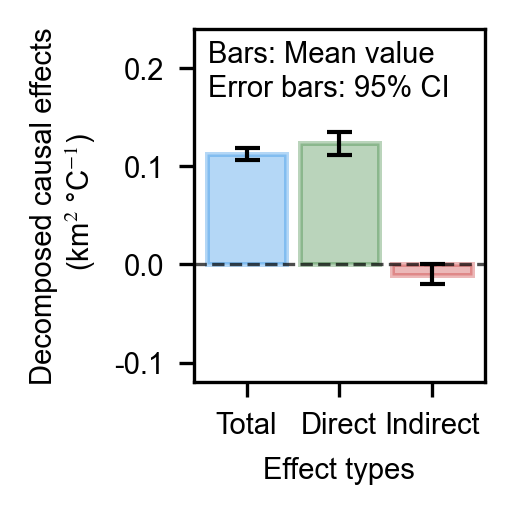

图像已保存至：D:\Python39\Code-NG\results\F2d.svg


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rcParams

# 绘图全局配置
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "svg.fonttype": "path"
}
rcParams.update(config)
out_path = r'D:\Python39\Code-NG\results\F2d.svg'
# ---------------------- 数据 ----------------------
effects = ['Total Effect', 'Direct Effect', 'Indirect Effect']
colors = ['#1e88e5', '#2e7d32', '#c62828']
#总效应 (MAAT→Lake): 0.113 (95% CI: [0.106, 0.119])
#直接效应 (MAAT→Lake|MAGT): 0.124 (95% CI: [0.112, 0.135])
#间接效应 (MAAT→MAGT→Lake): -0.011 (95% CI: [-0.020, -0.000])

boot_means = [0.113, 0.124, -0.011]
boot_lower = [0.106, 0.112, -0.020]
boot_upper = [0.119, 0.135, -0.000]

# 上下误差
boot_errors = [
    [boot_means[i] - boot_lower[i] for i in range(3)],
    [boot_upper[i] - boot_means[i] for i in range(3)]
]

# ---------------------- 创建画布 8 cm × 4 cm ----------------------
cm_to_inch = 1 / 2.54
fig_width = 4 * cm_to_inch
fig_height = 4.0 * cm_to_inch
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

bar_width = 0.3
inner_gap = 0.05
group_position = 0

boot_x = [
    group_position - bar_width - inner_gap,
    group_position,
    group_position + bar_width + inner_gap
]

# 绘制柱状图
bars = []
for i in range(3):
    bar = ax.bar(
        boot_x[i], boot_means[i], bar_width,
        facecolor=colors[i],
        alpha=0.33,
        edgecolor=colors[i],
        linewidth=1.2
    )
    bars.append(bar[0])

# 误差线
err = ax.errorbar(
    boot_x, boot_means, yerr=boot_errors,
    fmt='none', ecolor='black', capsize=3, linewidth=1.0
)

# ---------------------- 坐标轴设置 ----------------------
ax.set_ylabel('Decomposed causal effects\n (km$^{2}$ °C$^{-1}$)')
ax.set_xlabel('Effect types')
ax.set_xticks(boot_x)
ax.set_xticklabels(['Total', 'Direct', 'Indirect'])
ax.set_ylim(-0.12, 0.24)
ax.axhline(y=0, color='black', linestyle='--', alpha=0.7, linewidth=0.8)

# 保留完整四周边框
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)

# ===================== 注释文本=====================
text_note = 'Bars: Mean value\nError bars: 95% CI'
ax.text(0.05, 0.97, text_note, transform=ax.transAxes,
        ha='left', va='top', fontsize=7, linespacing=1.3)

plt.tight_layout(pad=0.3)

# 输出SVG路径
plt.savefig(out_path, format='svg', bbox_inches='tight')
plt.show()
plt.close()
print(f"图像已保存至：{out_path}")

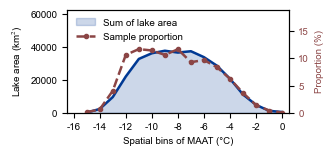

=== 数据统计信息 ===
总样本量：83226
未筛选数据总累加面积：316212.88 km²
筛选后数据总累加面积：316212.88 km²
筛选后面积占比：100.00%
最大分箱样本比例：11.71%

矢量SVG已保存至：D:\Dowhy\NG_2026_8\F1b.svg


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator

# ===================== 1. 全局配置=====================
config = {
    "font.family": 'Arial',
    "font.size": 7,          
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize":7,   
}
rcParams.update(config)

df = pd.read_csv(r'D:\Python39\Code-NG\data\Data_all.csv').copy()
fig_path=r"D:\Python39\Code-NG\results\F1b.svg"

# ===================== 2. 核心函数（平滑函数） =====================
def simple_smooth(data, window=3):
    """模拟Excel移动平均的平滑函数（和原代码一致）"""
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 3. 数据读取与预处理 =====================
# 读取原始数据


df_hist_original = df[(df['Pf_mean'] < 0)]

bins = np.arange(-17, 1, 1)  # 分箱边界

# ===================== 4. 处理未筛选数据 =====================
df_unfiltered = df_hist_original.copy()
# 计算总样本量（用于计算比例）
total_samples = len(df_unfiltered)
# Grid_Area加权
df_unfiltered['Area_mean_weighted'] = df_unfiltered['mean_LSED']
# 分箱处理
df_unfiltered['TAS_bin'] = pd.cut(df_unfiltered['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_unfiltered['TAS_bin_label'] = df_unfiltered['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_unfiltered = df_unfiltered.dropna(subset=['TAS_bin_label']).copy()
df_unfiltered['TAS_bin_label'] = df_unfiltered['TAS_bin_label'].astype(int)
# 分箱累加 + 统计分箱样本数
binned_unfiltered = df_unfiltered.groupby('TAS_bin_label', observed=True).agg(
    area_sum=('Area_mean_weighted', 'sum'),
    sample_count=('TAS_bin_label', 'count')  # 统计每个温度分箱的样本数量
).reset_index().sort_values('TAS_bin_label')
# 筛选有效温度范围（-16~0）+ 平滑
binned_unfiltered = binned_unfiltered[
    (binned_unfiltered['TAS_bin_label'] >= -16) & (binned_unfiltered['TAS_bin_label'] <= 0)
].sort_values('TAS_bin_label').reset_index(drop=True)
binned_unfiltered['area_sum_smooth'] = simple_smooth(binned_unfiltered['area_sum'], window=3)
# 计算分箱样本量占总样本的比例
binned_unfiltered['sample_ratio'] = binned_unfiltered['sample_count'] / total_samples * 100

# ===================== 5. 处理筛选后数据 =====================
df_filtered = df_hist_original[(df_hist_original['ERA_TAS'] > -16)].copy()
df_filtered = df_filtered
# Grid_Area加权
df_filtered['Area_mean_weighted'] = df_filtered['mean_LSED'] 
# 分箱处理
df_filtered['TAS_bin'] = pd.cut(df_filtered['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_filtered['TAS_bin_label'] = df_filtered['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_filtered = df_filtered.dropna(subset=['TAS_bin_label']).copy()
df_filtered['TAS_bin_label'] = df_filtered['TAS_bin_label'].astype(int)
# 分箱累加
binned_filtered = df_filtered.groupby('TAS_bin_label', observed=True).agg(
    area_sum=('Area_mean_weighted', 'sum')
).reset_index().sort_values('TAS_bin_label')
# 筛选有效温度范围（-16~0）+ 平滑
binned_filtered = binned_filtered[
    (binned_filtered['TAS_bin_label'] >= -16) & (binned_filtered['TAS_bin_label'] <= 0)
].sort_values('TAS_bin_label').reset_index(drop=True)
binned_filtered['area_sum_smooth'] = simple_smooth(binned_filtered['area_sum'], window=3)

# ===================== 6. 数据对齐 =====================
merged_data = pd.merge(
    binned_unfiltered[['TAS_bin_label', 'area_sum_smooth', 'sample_ratio']].rename(columns={'area_sum_smooth': 'unfiltered'}),
    binned_filtered[['TAS_bin_label', 'area_sum_smooth']].rename(columns={'area_sum_smooth': 'filtered'}),
    on='TAS_bin_label',
    how='outer'
).fillna(0).sort_values('TAS_bin_label')

# ===================== 7. 绘制双轴图：8.5cm宽 × 5cm高 =====================
# cm转英寸：1英寸=2.54cm
fig_width_cm = 8.5
fig_height_cm = 4
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()  # 主Y轴：湖泊面积
# 缩小边距适配小尺寸画布
plt.subplots_adjust(left=0.18, right=0.82, top=0.88, bottom=0.18)

# ---------- 主Y轴：绘制原有面积图----------
ax.fill_between(
    merged_data['TAS_bin_label'],
    merged_data['unfiltered'],
    0,
    color='#003994',
    alpha=0.2,
    label='Sum of lake area'
)
ax.plot(
    merged_data['TAS_bin_label'],
    merged_data['unfiltered'],
    color='#003994',
    linewidth=1.8,  
    zorder=5
)

# ---------- 副Y轴：绘制分箱样本量占比 ----------
ax2 = ax.twinx()  # 创建双Y轴
ax2.plot(
    merged_data['TAS_bin_label'],
    merged_data['sample_ratio'],
    color='#8B4545',
    linewidth=1.8,
    linestyle='--',
    marker='o',
    markersize=3,  # 缩小标记适配小图
    label='Sample proportion'
)

# ===================== 8. 双轴样式设置 =====================
# 主Y轴（面积）
ax.set_ylim(bottom=0, top=63000)
ax.set_xlabel('Spatial bins of MAAT (°C)', fontsize=7)
ax.set_xlim(-16.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.set_ylabel('Lake area (km$^{2}$)', color='black', fontsize=7)
ax.tick_params(axis='y', labelcolor='black', labelsize=7)
ax.tick_params(axis='x', labelsize=7)

# 副Y轴（样本比例）
ax2.set_ylabel('Proportion (%)', color='#8B4545', fontsize=7)
ax2.tick_params(axis='y', labelcolor='#8B4545', labelsize=7)
ax2.set_ylim(0, 19)
ax2.yaxis.set_major_locator(MultipleLocator(5))

# 统一图例
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=False, fontsize=7)

# ===================== 9. 输出SVG矢量图（ =====================
plt.tight_layout()
plt.savefig(fig_path, format="svg", bbox_inches="tight")
plt.show()
plt.close() 

# ===================== 10. 输出统计 =====================
print("=== 数据统计信息 ===")
print(f"总样本量：{total_samples}")
print(f"未筛选数据总累加面积：{merged_data['unfiltered'].sum():.2f} km²")
print(f"筛选后数据总累加面积：{merged_data['filtered'].sum():.2f} km²")
print(f"筛选后面积占比：{merged_data['filtered'].sum()/merged_data['unfiltered'].sum()*100:.2f}%")
print(f"最大分箱样本比例：{merged_data['sample_ratio'].max():.2f}%")
print(f"\n矢量SVG已保存至：D:\\Dowhy\\NG_2026_8\\F1b.svg")

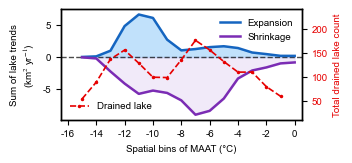

✅ 尺寸严格锁定：宽度8.5cm × 高度4cm，保存：D:\Python39\Code-NG\results\F1e.svg
=== 湖泊趋势统计 ===
扩张总量：29.75 km² yr⁻¹
萎缩总量：-62.17 km² yr⁻¹
净变化量：-32.42 km² yr⁻¹
有效非0排水分箱数量：15


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os

# ===================== 1. 全局统一配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7
}
rcParams.update(config)

f_path=r'D:\Dowhy\NG_2026_8\Data_all.csv'
output_dir = r"D:\Python39\Code-NG\results"
# ===================== 2. 通用平滑函数 =====================
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 3. 读取数据 =====================
# 主趋势数据

df_main = df_main[(df_main['Pf_mean'] < 0)]

df_drain = pd.read_csv(f_path, low_memory=False, encoding="utf-8-sig")
df_drain = df_drain[df_drain["drainage_flag"] != 0].copy()

bins = np.arange(-17, 1, 1)

# ---------------------- 处理主图：正负slope面积图 ----------------------
df_main['positive_slope'] = df_main['sen_slope_LSED'].apply(lambda x: x if x >= 0 else 0)
df_main['negative_slope'] = df_main['sen_slope_LSED'].apply(lambda x: x if x < 0 else 0)

df_main['TAS_bin'] = pd.cut(df_main['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_main['TAS_bin_label'] = df_main['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_main = df_main.dropna(subset=['TAS_bin_label']).copy()
df_main['TAS_bin_label'] = df_main['TAS_bin_label'].astype(int)

binned_trend = df_main.groupby('TAS_bin_label', observed=True).agg(
    positive_sum=('positive_slope', 'sum'),
    negative_sum=('negative_slope', 'sum'),
).reset_index().sort_values('TAS_bin_label')

# 限定-16~0区间
binned_trend = binned_trend[
    (binned_trend['TAS_bin_label'] >= -16) & (binned_trend['TAS_bin_label'] <= 0)
].reset_index(drop=True)

binned_trend['positive_smooth'] = simple_smooth(binned_trend['positive_sum'], window=3)
binned_trend['negative_smooth'] = simple_smooth(binned_trend['negative_sum'], window=3)

# ---------------------- 处理副轴：Drainage_count合计平滑曲线 ----------------------
df_drain['TAS_bin'] = pd.cut(df_drain['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_drain['TAS_bin_label'] = df_drain['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_drain = df_drain.dropna(subset=['TAS_bin_label']).copy()
df_drain['TAS_bin_label'] = df_drain['TAS_bin_label'].astype(int)

binned_drain = df_drain.groupby('TAS_bin_label').agg(
    total_drain_count=('Drainage_count', 'sum')
).reset_index()

binned_drain = binned_drain[
    (binned_drain['TAS_bin_label'] >= -16) & (binned_drain['TAS_bin_label'] <= 0)
].sort_values('TAS_bin_label').reset_index(drop=True)

binned_drain['drain_smooth'] = simple_smooth(binned_drain['total_drain_count'], window=3)

# 合并X轴，剔除drainage=0的点，只保留>0数据
merge_all = pd.merge(
    binned_trend[['TAS_bin_label']],
    binned_drain[['TAS_bin_label', 'drain_smooth']],
    on='TAS_bin_label',
    how='left'
)
merge_all = merge_all[merge_all['drain_smooth'] > 0].copy()

x_tick_all = merge_all['TAS_bin_label'].values
drain_curve_y = merge_all['drain_smooth'].values

# ===================== 4. 绘图尺寸 =====================
fig_width_cm = 8.5
fig_height_cm = 4
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()
ax2 = ax.twinx()
plt.subplots_adjust(left=0.16, right=0.88, top=0.92, bottom=0.22)

# ========== 配色 ==========
color_exp_fill = '#64b5f6'
color_exp_line = '#1565c0'
color_shr_line = '#7b2cb4'
color_shr_fill = '#dcccf2'
color_drain_line = '#e60000'

# 扩张面积
line_exp, = ax.plot(
    binned_trend['TAS_bin_label'],
    binned_trend['positive_smooth'],
    color=color_exp_line,
    linewidth=1.8,
    zorder=5
)
ax.fill_between(
    binned_trend['TAS_bin_label'],
    binned_trend['positive_smooth'],
    0,
    color=color_exp_fill,
    alpha=0.4
)

# 萎缩面积
line_shr, = ax.plot(
    binned_trend['TAS_bin_label'],
    binned_trend['negative_smooth'],
    color=color_shr_line,
    linewidth=1.8,
    zorder=5
)
ax.fill_between(
    binned_trend['TAS_bin_label'],
    binned_trend['negative_smooth'],
    0,
    color=color_shr_fill,
    alpha=0.4
)

# 零值虚线
ax.axhline(y=0, color='black', linestyle='--', alpha=0.7, linewidth=1)

# 副轴排水曲线
line_drain, = ax2.plot(
    x_tick_all,
    drain_curve_y,
    color=color_drain_line,
    linewidth=1.2,
    linestyle='--',
    marker='o',
    markersize=1.5,
    label='Drained lake'
)

# ===================== 5. 坐标轴 =====================
ax.set_xlabel('Spatial bins of MAAT (°C)', fontsize=7)
ax.set_ylabel("Sum of lake trends\n(km$^{2}$ yr$^{-1}$)", color='black', fontsize=7)
ax.set_xlim(-16.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.tick_params(axis='both', labelsize=7)

ax2.set_ylim(10, 240)
ax2.set_ylabel('Total drained lake count', color=color_drain_line, fontsize=7)
ax2.tick_params(axis='y', labelcolor=color_drain_line, labelsize=7)
ax2.grid(False)

# ===================== 双图例分开摆放 =====================
# 右上角：Expansion + Shrinkage
leg1 = ax.legend(
    handles=[line_exp, line_shr],
    labels=['Expansion', 'Shrinkage'],
    loc='upper right',
    frameon=False,
    fontsize=7
)
ax.add_artist(leg1)

# 右下角：Drained lake
ax.legend(
    handles=[line_drain],
    labels=['Drained lake'],
    loc='lower left',
    frameon=False,
    fontsize=7
)

# 边框统一线宽
for spine in ax.spines.values():
    spine.set_linewidth(1)
for spine in ax2.spines.values():
    spine.set_linewidth(1)

# ===================== 6. 导出  =====================

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F1e.svg")

plt.savefig(save_path, format="svg")
plt.show()
plt.close()

# ===================== 7. 控制台输出 =====================
print(f"✅ 尺寸严格锁定：宽度8.5cm × 高度4cm，保存：{save_path}")
print("=== 湖泊趋势统计 ===")
print(f"扩张总量：{binned_trend['positive_sum'].sum():.2f} km² yr⁻¹")
print(f"萎缩总量：{binned_trend['negative_sum'].sum():.2f} km² yr⁻¹")
print(f"净变化量：{binned_trend['positive_sum'].sum() + binned_trend['negative_sum'].sum():.2f} km² yr⁻¹")
print(f"有效非0排水分箱数量：{len(merge_all)}")

数据筛选阶段统计（样本量及占比）：
1. 原始数据总量：84,388 条
【未执行任何筛选，全部原始网格 Total_ITE 总和】 = 5668.090153
2. 基础筛选（GLDAS_TAS > -18）后：84,388 条 | 占原始数据比例：100.00%
3. 显著性筛选后：37,023 条
   - 占基础筛选数据比例：43.87%
   - 占原始数据比例：43.87%
【显著性筛选保留网格 Total_ITE 总和】 = 2974.787906


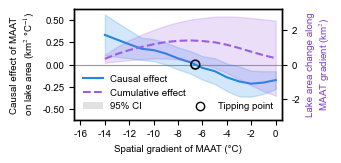


✅ 图像保存成功，尺寸：8.5cm × 4cm，路径：D:\Python39\Code-NG\results\F2b.svg

Tipping point detected at MAAT: -6.59 °C

【置信区间与0轴交点（搜索范围 -16 ~ 0 ℃）】
置信下限曲线交点 TAS = -9.00 °C
置信上限曲线交点 TAS = -3.63 °C
拐点置信区间：[-9.00, -3.63] °C
【显著性筛选保留网格 Total_ITE 总和】 = 2974.787906
===== MAAT阈值 -6.6 °C 分组统计（仅显著网格 | 总量比值法） =====
【阈值下方 ERA_TAS < -6.6 °C 样本量】: 28,392
  组内总湖泊面积(km²): 84923.0731
  ITE总和(km² °C⁻¹): 3871.8484
  单网格平均ITE(km² °C⁻¹): 0.1364
  区域湖泊面积相对变化率(% °C⁻¹): 4.5592
------------------------------------------------------------
【阈值上方 ERA_TAS ≥ -6.6 °C 样本量】: 8,631
  组内总湖泊面积(km²): 32989.7762
  ITE总和(km² °C⁻¹): -897.0605
  单网格平均ITE(km² °C⁻¹): -0.1039
  区域湖泊面积相对变化率(% °C⁻¹): -2.7192


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ===================== 1. 全局统一配置=====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7,
    "svg.fonttype": "path"
}
rcParams.update(config)

df_hist_original = pd.read_csv(r'D:\Python39\Code-NG\data\ITE_LSED_ERA.csv').copy()
output_dir = r"D:\Python39\Code-NG\results"
# ===================== 核心函数：简单平滑函数 =====================
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 1. 数据读取 =====================

total_original = len(df_hist_original)
print("="*60)
print("数据筛选阶段统计（样本量及占比）：")
print(f"1. 原始数据总量：{total_original:,} 条")
sum_total_ite_raw = df_hist_original['Total_ITE'].sum()
print(f"【未执行任何筛选，全部原始网格 Total_ITE 总和】 = {sum_total_ite_raw:.6f}")

# ===================== 2. 基础筛选 =====================
df_hist = df_hist_original.copy()
total_after_basic_filter = len(df_hist)
basic_filter_ratio = (total_after_basic_filter / total_original) * 100
print(f"2. 基础筛选（GLDAS_TAS > -18）后：{total_after_basic_filter:,} 条 | 占原始数据比例：{basic_filter_ratio:.2f}%")

# ===================== 3. 显著性筛选 =====================
significant_filter = (
    ~((df_hist['Total_lower'] < 0) & (df_hist['Total_upper'] > 0))
)
df_hist = df_hist[significant_filter].copy()
total_after_significant_filter = len(df_hist)

significant_ratio_vs_basic = (total_after_significant_filter / total_after_basic_filter) * 100
significant_ratio_vs_original = (total_after_significant_filter / total_original) * 100
print(f"3. 显著性筛选后：{total_after_significant_filter:,} 条")
print(f"   - 占基础筛选数据比例：{significant_ratio_vs_basic:.2f}%")
print(f"   - 占原始数据比例：{significant_ratio_vs_original:.2f}%")

sum_total_ite_sig = df_hist['Total_ITE'].sum()
print(f"【显著性筛选保留网格 Total_ITE 总和】 = {sum_total_ite_sig:.6f}")
print("="*60)

if len(df_hist) == 0:
    raise ValueError("无显著性ITE数据（所有置信区间都包含0）")

result_tas = df_hist.copy()

# ===================== 4. 温度分箱 =====================
bins = np.arange(-17, 1, 1)
df_hist['TAS_bin'] = pd.cut(df_hist['ERA_TAS'], bins=bins, right=True, include_lowest=True)
df_hist['TAS_bin_label'] = df_hist['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
df_hist = df_hist.dropna(subset=['TAS_bin_label']).copy()
df_hist['TAS_bin_label'] = df_hist['TAS_bin_label'].astype(int)

result_tas['TAS_bin'] = pd.cut(result_tas['ERA_TAS'], bins=bins, right=True, include_lowest=True)
result_tas['TAS_bin_label'] = result_tas['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
result_tas = result_tas.dropna(subset=['TAS_bin_label']).copy()
result_tas['TAS_bin_label'] = result_tas['TAS_bin_label'].astype(int)

# 分箱聚合
binned_tas = result_tas.groupby('TAS_bin_label', observed=True).agg(
    total_mean=('Total_ITE', 'mean'),
    total_lower_mean=('Total_lower', 'mean'),
    total_upper_mean=('Total_upper', 'mean')
).reset_index().sort_values('TAS_bin_label')

# 筛选有效温度区间
binned_stats = binned_tas[
    (binned_tas['TAS_bin_label'] >= -16) &
    (binned_tas['TAS_bin_label'] <= 0)
].sort_values('TAS_bin_label').reset_index(drop=True)

# ===================== 5. 数据平滑 + 累积和 =====================
binned_stats['total_mean_smooth'] = simple_smooth(binned_stats['total_mean'], window=3)
binned_stats['total_lower_mean_smooth'] = simple_smooth(binned_stats['total_lower_mean'], window=3)
binned_stats['total_upper_mean_smooth'] = simple_smooth(binned_stats['total_upper_mean'], window=3)

binned_stats['total_mean_cumsum'] = binned_stats['total_mean_smooth'].cumsum()
binned_stats['total_lower_cumsum'] = binned_stats['total_lower_mean_smooth'].cumsum()
binned_stats['total_upper_cumsum'] = binned_stats['total_upper_mean_smooth'].cumsum()

# ===================== 6. 原始临界点计算（范围 -16 ~ 0） =====================
tipping_point = None
tipping_range = binned_stats[
    (binned_stats['TAS_bin_label'] >= -16) &
    (binned_stats['TAS_bin_label'] < 0)
].sort_values('TAS_bin_label', ascending=False).reset_index(drop=True)

if len(tipping_range) >= 2:
    for i in range(len(tipping_range) - 1):
        x1, y1 = tipping_range.iloc[i]['TAS_bin_label'], tipping_range.iloc[i]['total_mean_smooth']
        x2, y2 = tipping_range.iloc[i+1]['TAS_bin_label'], tipping_range.iloc[i+1]['total_mean_smooth']
        if y1 < 0 and y2 > 0:
            k = (y2 - y1) / (x2 - x1)
            tipping_x = x1 - (y1 / k)
            tipping_point = (tipping_x, 0)
            break

# ===================== 通用0轴交点检测【搜索区间 -16 ~ 0】 =====================
def get_cross_zero_universal(x_series, y_series, search_min=-16, search_max=0):
    df = pd.DataFrame({'x': x_series, 'y': y_series}).copy()
    df_search = df[(df['x'] >= search_min) & (df['x'] <= search_max)].sort_values('x').reset_index(drop=True)
    cross_temp = None
    if len(df_search) >= 2:
        for i in range(len(df_search)-1):
            x1, y1 = df_search.iloc[i]['x'], df_search.iloc[i]['y']
            x2, y2 = df_search.iloc[i+1]['x'], df_search.iloc[i+1]['y']
            if np.sign(y1) != np.sign(y2):
                k = (y2 - y1) / (x2 - x1)
                cross_temp = x1 - (y1 / k)
                break
    return cross_temp

mean_cross = get_cross_zero_universal(binned_stats['TAS_bin_label'], binned_stats['total_mean_smooth'])
ci_upper_cross = get_cross_zero_universal(binned_stats['TAS_bin_label'], binned_stats['total_upper_mean_smooth'])
ci_lower_cross = get_cross_zero_universal(binned_stats['TAS_bin_label'], binned_stats['total_lower_mean_smooth'])

# ===================== 7. 绘图 严格尺寸 8.5cm × 4cm =====================
fig_width_cm = 8.5
fig_height_cm = 4
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax2 = plt.gca()
ax2_right = ax2.twinx()
plt.subplots_adjust(left=0.19, right=0.81, top=0.92, bottom=0.22)

sum_line, = ax2.plot(
    binned_stats['TAS_bin_label'], binned_stats['total_mean_smooth'],
    '-', color='#1e88e5', linewidth=1.5, label='Causal effect'
)
# 蓝色置信区间阴影
ax2.fill_between(
    binned_stats['TAS_bin_label'],
    binned_stats['total_lower_mean_smooth'],
    binned_stats['total_upper_mean_smooth'],
    color='#1e88e5', alpha=0.2
)

cumsum_line, = ax2_right.plot(
    binned_stats['TAS_bin_label'], binned_stats['total_mean_cumsum'],
    '--', color='#9b5de5', linewidth=1.5, label='Cumulative effect'
)
# 紫色累积效应置信区间阴影
ax2_right.fill_between(
    binned_stats['TAS_bin_label'],
    binned_stats['total_lower_cumsum'],
    binned_stats['total_upper_cumsum'],
    color='#9b5de5', alpha=0.2
)

tipping_marker = None
if tipping_point is not None:
    tipping_marker = ax2.scatter(
        tipping_point[0], tipping_point[1],
        edgecolor='black', facecolor='none', s=40, linewidth=1.2, marker='o', zorder=5
    )

ax2.set_ylabel('Causal effect of MAAT\n on lake area (km$^{2}$ °C$^{-1}$)', color='#000000')
ax2_right.set_ylabel('Lake area change along\n MAAT gradient (km$^{2}$)', color='#7b3dc5')
ax2.set_xlabel('Spatial gradient of MAAT (°C)')
ax2.set_xlim(-16.5, 0.5)
ax2.set_ylim(-0.62, 0.62)
ax2_right.set_ylim(-3.2, 3.2)
ax2.xaxis.set_major_locator(MultipleLocator(2))
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.4, zorder=0, linewidth=0.8)

legend_elements_main = [
    sum_line,
    cumsum_line,
    Patch(facecolor='#888888', alpha=0.25, edgecolor=None, label='95% CI')
]
labels_main = ['Causal effect', 'Cumulative effect', '95% CI']
leg1 = ax2.legend(legend_elements_main, labels_main, loc='lower left', frameon=False, ncol=1)
ax2.add_artist(leg1)

if tipping_point is not None and tipping_marker is not None:
    legend_tip = [
        Line2D([], [], marker='o', linestyle='', markerfacecolor='none', markeredgecolor='black', markersize=6, label='Tipping point')
    ]
    ax2.legend(legend_tip, ['Tipping point'], loc='lower right', frameon=False)

for spine in ax2.spines.values():
    spine.set_linewidth(1)
for spine in ax2_right.spines.values():
    spine.set_linewidth(1)

# ===================== 8. 输出  =====================

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F2b.svg")

plt.savefig(save_path, format="svg")
plt.show()
plt.close()

# ===================== 控制台输出 =====================
print(f"\n✅ 图像保存成功，尺寸：8.5cm × 4cm，路径：{save_path}")
if tipping_point:
    print(f"\nTipping point detected at MAAT: {tipping_point[0]:.2f} °C")
else:
    print("\nNo tipping point detected in [-16, 0] °C range.")

print("\n" + "="*60)
print("【置信区间与0轴交点（搜索范围 -16 ~ 0 ℃）】")
if ci_lower_cross is not None:
    print(f"置信下限曲线交点 TAS = {ci_lower_cross:.2f} °C")
else:
    print("置信下限曲线未与0相交")
if ci_upper_cross is not None:
    print(f"置信上限曲线交点 TAS = {ci_upper_cross:.2f} °C")
else:
    print("置信上限曲线未与0相交")

cross_list = []
if ci_lower_cross is not None:
    cross_list.append(ci_lower_cross)
if ci_upper_cross is not None:
    cross_list.append(ci_upper_cross)
if len(cross_list) >= 2:
    print(f"拐点置信区间：[{min(cross_list):.2f}, {max(cross_list):.2f}] °C")
print("="*60)
sum_total_ite_sig = df_hist['Total_ITE'].sum()
print(f"【显著性筛选保留网格 Total_ITE 总和】 = {sum_total_ite_sig:.6f}")
print("="*60)

# ===================== 阈值 -6.6°C 分组统计 =====================
threshold_maat = -6.6
# 阈值下方：ERA_TAS < -6.6
group_below = df_hist[df_hist["ERA_TAS"] < threshold_maat].copy()
# 阈值上方：ERA_TAS >= -6.6
group_above = df_hist[df_hist["ERA_TAS"] >= threshold_maat].copy()

# -------- 下方组（< -6.6°C）--------
# 组内每个网格湖泊面积 = Grid_Area * Lake_density
group_below["lake_area_grid"] = group_below["Grid_Area"] * group_below["Lake_density"]
sum_lake_below = group_below["lake_area_grid"].sum()    # 组内总湖泊面积 km²
sum_ite_below = group_below["Total_ITE"].sum()          # 组内ITE总和 km²/°C
mean_ite_below = group_below["Total_ITE"].mean()         # 单网格平均ITE km²/°C
# 相对变化率 % °C⁻¹
pct_rate_below = (sum_ite_below / sum_lake_below) * 100

# -------- 上方组（>= -6.6°C）--------
group_above["lake_area_grid"] = group_above["Grid_Area"] * group_above["Lake_density"]
sum_lake_above = group_above["lake_area_grid"].sum()
sum_ite_above = group_above["Total_ITE"].sum()
mean_ite_above = group_above["Total_ITE"].mean()
pct_rate_above = (sum_ite_above / sum_lake_above) * 100

print(f"===== MAAT阈值 {threshold_maat:.1f} °C 分组统计（仅显著网格 | 总量比值法） =====")
print(f"【阈值下方 ERA_TAS < {threshold_maat:.1f} °C 样本量】: {len(group_below):,}")
print(f"  组内总湖泊面积(km²): {sum_lake_below:.4f}")
print(f"  ITE总和(km² °C⁻¹): {sum_ite_below:.4f}")
print(f"  单网格平均ITE(km² °C⁻¹): {mean_ite_below:.4f}")
print(f"  区域湖泊面积相对变化率(% °C⁻¹): {pct_rate_below:.4f}")
print("-"*60)
print(f"【阈值上方 ERA_TAS ≥ {threshold_maat:.1f} °C 样本量】: {len(group_above):,}")
print(f"  组内总湖泊面积(km²): {sum_lake_above:.4f}")
print(f"  ITE总和(km² °C⁻¹): {sum_ite_above:.4f}")
print(f"  单网格平均ITE(km² °C⁻¹): {mean_ite_above:.4f}")
print(f"  区域湖泊面积相对变化率(% °C⁻¹): {pct_rate_above:.4f}")
print("="*75)

if len(df_hist) == 0:
    raise ValueError("无显著性ITE数据（所有置信区间跨0网格已剔除）")

result_tas = df_hist.copy()

数据筛选阶段统计（样本量及占比）：
1. 原始数据总量：84,388 条
2. 基础筛选（ERA_TAS > -18）后：84,388 条 | 占原始数据比例：100.00%
3. 显著性筛选后：37,023 条
   - 占基础筛选数据比例：43.87%
   - 占原始数据比例：43.87%
✅ 6组分组完成，有效数据量：37,023 条
📊 各组样本量统计：
group
Lake-poor & Low ice content       8726
Lake-poor & High ice content      8186
Lake-rich & Low ice content       8002
Lake-poor & Median ice content    5175
Lake-rich & High ice content      4354
Lake-rich & Median ice content    2578
nan                                  2
Name: count, dtype: int64
✅ Lake-rich & High ice content 拐点：MAAT = -9.25 °C
✅ Lake-rich & Median ice content 拐点：MAAT = -8.16 °C
✅ Lake-rich & Low ice content 拐点：MAAT = -6.00 °C
✅ Lake-poor & High ice content 拐点：MAAT = -7.15 °C
✅ Lake-poor & Median ice content 拐点：MAAT = -5.29 °C
✅ Lake-poor & Low ice content 拐点：MAAT = -5.19 °C


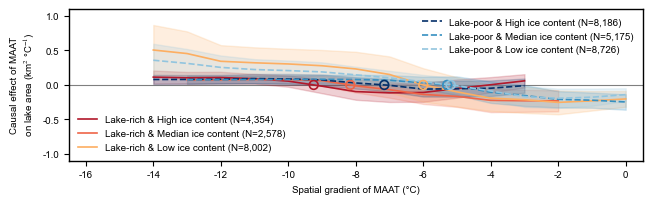


✅ 图像保存成功，尺寸：16cm × 5cm，路径：D:\Python39\Code-NG\results\F3a.svg


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os

# ===================== 全局统一配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7,
    "svg.fonttype": "path"
}
rcParams.update(config)

df_hist_original = pd.read_csv(r'D:\Python39\Code-NG\data\ITE_LSED_ERA.csv').copy()
output_dir = r"D:\Python39\Code-NG\results"
# ===================== 核心函数 =====================
def simple_smooth(data, window=3):
    """数据平滑"""
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

def get_cross_zero_universal(x_series, y_series, search_min=-16, search_max=0):
    """通用0轴交点检测（计算拐点）"""
    df = pd.DataFrame({'x': x_series, 'y': y_series}).copy()
    df_search = df[(df['x'] >= search_min) & (df['x'] <= search_max)].sort_values('x').reset_index(drop=True)
    cross_temp = None
    if len(df_search) >= 2:
        for i in range(len(df_search)-1):
            x1, y1 = df_search.iloc[i]['x'], df_search.iloc[i]['y']
            x2, y2 = df_search.iloc[i+1]['x'], df_search.iloc[i+1]['y']
            if np.sign(y1) != np.sign(y2):
                k = (y2 - y1) / (x2 - x1)
                cross_temp = x1 - (y1 / k)
                break
    return cross_temp

# ===================== 分组数据处理函数 =====================
def process_group_data(df_group, bins):
    """处理单个分组：温度分箱→聚合→平滑→计算瞬时效应"""
    # 温度分箱
    df_group['TAS_bin'] = pd.cut(df_group['ERA_TAS'], bins=bins, right=True, include_lowest=True)
    df_group['TAS_bin_label'] = df_group['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    df_group = df_group.dropna(subset=['TAS_bin_label']).copy()
    df_group['TAS_bin_label'] = df_group['TAS_bin_label'].astype(int)
    
    # 分箱聚合统计
    binned = df_group.groupby('TAS_bin_label', observed=True).agg(
        total_mean=('Total_ITE', 'mean'),    
        total_lower=('Total_lower', 'mean'),
        total_upper=('Total_upper', 'mean')
    ).reset_index().sort_values('TAS_bin_label')
    
    binned_stats = binned[
        (binned['TAS_bin_label'] >= -16) &
        (binned['TAS_bin_label'] <= 0)
    ].sort_values('TAS_bin_label').reset_index(drop=True)
    
    # 数据平滑（瞬时因果效应）
    binned_stats['mean_smooth'] = simple_smooth(binned_stats['total_mean'], window=3)
    binned_stats['lower_smooth'] = simple_smooth(binned_stats['total_lower'], window=3)
    binned_stats['upper_smooth'] = simple_smooth(binned_stats['total_upper'], window=3)
    
    return binned_stats

# ===================== 1. 数据读取 =====================


total_original = len(df_hist_original)
print("="*60)
print("数据筛选阶段统计（样本量及占比）：")
print(f"1. 原始数据总量：{total_original:,} 条")

# ===================== 2. 基础筛选 =====================
df_hist = df_hist_original[(df_hist_original['ERA_TAS'] > -18)].copy()
total_after_basic_filter = len(df_hist)
basic_filter_ratio = (total_after_basic_filter / total_original) * 100
print(f"2. 基础筛选（ERA_TAS > -18）后：{total_after_basic_filter:,} 条 | 占原始数据比例：{basic_filter_ratio:.2f}%")

# ===================== 3. 显著性筛选 =====================
significant_filter = (
    ~((df_hist['Total_lower'] < 0) & (df_hist['Total_upper'] > 0)) 
)
df_hist = df_hist[significant_filter].copy()
total_after_significant_filter = len(df_hist)

significant_ratio_vs_basic = (total_after_significant_filter / total_after_basic_filter) * 100
significant_ratio_vs_original = (total_after_significant_filter / total_original) * 100
print(f"3. 显著性筛选后：{total_after_significant_filter:,} 条")
print(f"   - 占基础筛选数据比例：{significant_ratio_vs_basic:.2f}%")
print(f"   - 占原始数据比例：{significant_ratio_vs_original:.2f}%")
print("="*60)

if len(df_hist) == 0:
    raise ValueError("无显著性ITE数据（所有置信区间都包含0）")

# ===================== 6组分组逻辑 =====================
df_hist['ratio'] = df_hist['Lake_density']*100

conditions = [
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 1),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 1),
]

choices = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]

df_hist['group'] = np.select(conditions, choices, default=np.nan)
df_hist = df_hist.dropna(subset=['group']).copy()

group_counts = df_hist['group'].value_counts().to_dict()
print(f"✅ 6组分组完成，有效数据量：{len(df_hist):,} 条")
print(f"📊 各组样本量统计：\n{df_hist['group'].value_counts()}")
print("="*60)

# ===================== 分组处理 =====================
bins = np.arange(-17, 1, 1)
group_order = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]
group_results = {}

for group_name in group_order:
    if group_name in df_hist['group'].values:
        group_df = df_hist[df_hist['group'] == group_name].copy()
        group_results[group_name] = process_group_data(group_df, bins)
    else:
        print(f"⚠️ 分组 {group_name} 无数据，跳过")

# ===================== 样式配置 =====================
style_config = {
    'Lake-rich & High ice content':   {'color': '#b2182b', 'linestyle': '-'},
    'Lake-rich & Median ice content': {'color': '#ef6548', 'linestyle': '-'},
    'Lake-rich & Low ice content':    {'color': '#fdae61', 'linestyle': '-'},
    'Lake-poor & High ice content':   {'color': '#05306a', 'linestyle': '--'},
    'Lake-poor & Median ice content': {'color': '#3690c1', 'linestyle': '--'},
    'Lake-poor & Low ice content':    {'color': '#92c5de', 'linestyle': '--'}
}

# ===================== 绘图：尺寸 16cm × 5cm =====================
fig_width_cm = 18.8
fig_height_cm = 5
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()

# 图例容器
rich_handles = []
rich_labels = []
poor_handles = []
poor_labels = []

# 循环绘制所有分组
for group_name, stats in group_results.items():
    style = style_config[group_name]
    color = style['color']
    linestyle = style['linestyle']
    sample_num = group_counts[group_name]
    label = f"{group_name} (N={sample_num:,})"
    
    # 绘制曲线与置信区间
    line1 = ax.plot(
        stats['TAS_bin_label'], stats['mean_smooth'],
        color=color, linewidth=1.2, linestyle=linestyle
    )[0]
    ax.fill_between(
        stats['TAS_bin_label'], stats['lower_smooth'], stats['upper_smooth'],
        color=color, alpha=0.2
    )
    
    # 拐点检测与标记
    tipping_x = get_cross_zero_universal(stats['TAS_bin_label'], stats['mean_smooth'])
    if tipping_x is not None:
        ax.scatter(
            tipping_x, 0,
            edgecolor=color, facecolor='none', s=40, linewidth=1.2,
            marker='o', zorder=10
        )
        print(f"✅ {group_name} 拐点：MAAT = {tipping_x:.2f} °C")
    else:
        print(f"❌ {group_name} 未检测到拐点")
    
    if 'Lake-rich' in group_name:
        rich_handles.append(line1)
        rich_labels.append(label)
    else:
        poor_handles.append(line1)
        poor_labels.append(label)

# 双图例
legend1 = ax.legend(rich_handles, rich_labels, loc='lower left', frameon=False)
ax.add_artist(legend1)
ax.legend(poor_handles, poor_labels, loc='upper right', frameon=False)

# 坐标轴设置
ax.set_xlabel('Spatial gradient of MAAT (°C)')
ax.set_ylabel('Causal effect of MAAT\n on lake area (km$^{2}$ °C$^{-1}$)')
ax.set_xlim(-16.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.axhline(y=0, color='black', linestyle='-', alpha=0.5, zorder=0, linewidth=0.8)
ax.set_ylim(-1.1, 1.1)
ax.set_yticks([-1,-0.5,0, 0.5,1])

# 统一边框宽度
for spine in ax.spines.values():
    spine.set_linewidth(1)

# ===================== 输出路径 =====================

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F3a.svg")
plt.savefig(save_path, format="svg", bbox_inches='tight')
plt.show()
plt.close()

# ===================== 控制台输出 =====================
print(f"\n✅ 图像保存成功，尺寸：16cm × 5cm，路径：{save_path}")
print("="*60)

数据筛选阶段统计（样本量及占比）：
1. 原始数据总量：84,388 条
2. 基础筛选（ERA_TAS > -18）后：84,388 条 | 占原始数据比例：100.00%
3. 显著性筛选后：18,088 条
   - 占基础筛选数据比例：21.43%
   - 占原始数据比例：21.43%
✅ 6组分组完成，有效数据量：18,088 条
📊 各组样本量统计：
group
Lake-rich & Low ice content       3954
Lake-poor & High ice content      3432
Lake-rich & High ice content      3380
Lake-poor & Low ice content       3065
Lake-poor & Median ice content    2585
Lake-rich & Median ice content    1667
nan                                  5
Name: count, dtype: int64


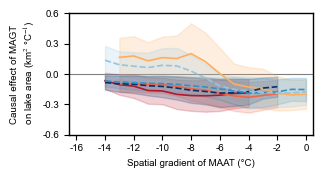


✅ 图像保存成功，尺寸：8cm × 5cm，路径：D:\Python39\Code-NG\results\F3b.svg


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os

# ===================== 全局统一配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7,
    "svg.fonttype": "path"
}
rcParams.update(config)
df_hist_original = pd.read_csv(r'D:\Python39\Code-NG\data\ITE_LSED_ERA.csv').copy()
output_dir = r"D:\Python39\Code-NG\results"
# ===================== 核心函数 =====================
def simple_smooth(data, window=3):
    """数据平滑"""
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 分组数据处理函数 =====================
def process_group_data(df_group, bins):
    """处理单个分组：温度分箱→聚合→平滑→Media效应"""
    # 温度分箱
    df_group['TAS_bin'] = pd.cut(df_group['ERA_TAS'], bins=bins, right=True, include_lowest=True)
    df_group['TAS_bin_label'] = df_group['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    df_group = df_group.dropna(subset=['TAS_bin_label']).copy()
    df_group['TAS_bin_label'] = df_group['TAS_bin_label'].astype(int)
    
    # 分箱聚合统计
    binned = df_group.groupby('TAS_bin_label', observed=True).agg(
        indirect_mean=('Media_ITE', 'mean'),    
        indirect_lower=('Media_lower', 'mean'),
        indirect_upper=('Media_upper', 'mean')
    ).reset_index().sort_values('TAS_bin_label')
    
    # 筛选有效温度区间
    binned_stats = binned[
        (binned['TAS_bin_label'] >= -16) &
        (binned['TAS_bin_label'] <= 0)
    ].sort_values('TAS_bin_label').reset_index(drop=True)
    
    # 数据平滑
    binned_stats['mean_smooth'] = simple_smooth(binned_stats['indirect_mean'], window=3)
    binned_stats['lower_smooth'] = simple_smooth(binned_stats['indirect_lower'], window=3)
    binned_stats['upper_smooth'] = simple_smooth(binned_stats['indirect_upper'], window=3)
    
    return binned_stats

# ===================== 1. 数据读取 =====================


total_original = len(df_hist_original)
print("="*60)
print("数据筛选阶段统计（样本量及占比）：")
print(f"1. 原始数据总量：{total_original:,} 条")

# ===================== 2. 基础筛选 =====================
df_hist = df_hist_original[(df_hist_original['ERA_TAS'] > -18)].copy()
total_after_basic_filter = len(df_hist)
basic_filter_ratio = (total_after_basic_filter / total_original) * 100
print(f"2. 基础筛选（ERA_TAS > -18）后：{total_after_basic_filter:,} 条 | 占原始数据比例：{basic_filter_ratio:.2f}%")

# ===================== 3. 显著性筛选 =====================
significant_filter = (
    ~((df_hist['Media_lower'] < 0) & (df_hist['Media_upper'] > 0)) 
)
df_hist = df_hist[significant_filter].copy()
total_after_significant_filter = len(df_hist)

significant_ratio_vs_basic = (total_after_significant_filter / total_after_basic_filter) * 100
significant_ratio_vs_original = (total_after_significant_filter / total_original) * 100
print(f"3. 显著性筛选后：{total_after_significant_filter:,} 条")
print(f"   - 占基础筛选数据比例：{significant_ratio_vs_basic:.2f}%")
print(f"   - 占原始数据比例：{significant_ratio_vs_original:.2f}%")
print("="*60)

if len(df_hist) == 0:
    raise ValueError("无显著性Media ITE数据（所有置信区间都包含0）")

# ===================== 6组分组逻辑 =====================
df_hist['ratio'] = (df_hist['Lake_density'] * 100)

conditions = [
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 1),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 1),
]

choices = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]

df_hist['group'] = np.select(conditions, choices, default=np.nan)
df_hist = df_hist.dropna(subset=['group']).copy()

group_counts = df_hist['group'].value_counts().to_dict()
print(f"✅ 6组分组完成，有效数据量：{len(df_hist):,} 条")
print(f"📊 各组样本量统计：\n{df_hist['group'].value_counts()}")
print("="*60)

# ===================== 分组处理 =====================
bins = np.arange(-17, 1, 1)
group_order = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]
group_results = {}

for group_name in group_order:
    if group_name in df_hist['group'].values:
        group_df = df_hist[df_hist['group'] == group_name].copy()
        group_results[group_name] = process_group_data(group_df, bins)
    else:
        print(f"⚠️ 分组 {group_name} 无数据，跳过")

# ===================== 样式配置 =====================
style_config = {
    'Lake-rich & High ice content':   {'color': '#b2182b', 'linestyle': '-'},
    'Lake-rich & Median ice content': {'color': '#ef6548', 'linestyle': '-'},
    'Lake-rich & Low ice content':    {'color': '#fdae61', 'linestyle': '-'},
    'Lake-poor & High ice content':   {'color': '#05306a', 'linestyle': '--'},
    'Lake-poor & Median ice content': {'color': '#3690c1', 'linestyle': '--'},
    'Lake-poor & Low ice content':    {'color': '#92c5de', 'linestyle': '--'}
}

# ===================== 绘图：尺寸 8cm × 5cm，无图例 =====================
fig_width_cm = 8
fig_height_cm = 4
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()

# 循环绘制所有分组
for group_name, stats in group_results.items():
    style = style_config[group_name]
    color = style['color']
    linestyle = style['linestyle']
    
    ax.plot(
        stats['TAS_bin_label'], stats['mean_smooth'],
        color=color, linewidth=1.2, linestyle=linestyle
    )
    ax.fill_between(
        stats['TAS_bin_label'], stats['lower_smooth'], stats['upper_smooth'],
        color=color, alpha=0.2
    )

# 坐标轴设置
ax.set_xlabel('Spatial gradient of MAAT (°C)')
ax.set_ylabel('Causal effect of MAGT\n on lake area (km$^{2}$ °C$^{-1}$)')
ax.set_xlim(-16.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.axhline(y=0, color='black', linestyle='-', alpha=0.5, zorder=0, linewidth=0.8)
ax.set_yticks([-0.6,-0.3,0,0.3, 0.6])

# 统一边框宽度
for spine in ax.spines.values():
    spine.set_linewidth(1)

# ===================== 输出路径 =====================

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F3b.svg")
plt.savefig(save_path, format="svg", bbox_inches='tight')
plt.show()
plt.close()

# ===================== 控制台输出 =====================
print(f"\n✅ 图像保存成功，尺寸：8cm × 5cm，路径：{save_path}")
print("="*60)

数据筛选阶段统计（样本量及占比）：
1. 原始数据总量：83,226 条
2. 基础筛选（ERA_TAS > -18）后：83,226 条 | 占原始数据比例：100.00%
3. 显著性筛选后：9,303 条
   - 占基础筛选数据比例：11.18%
   - 占原始数据比例：11.18%
✅ 6组分组完成，有效数据量：9,303 条
📊 各组样本量统计：
group
Lake-rich & Low ice content       4401
Lake-poor & Low ice content       2397
Lake-poor & High ice content       798
Lake-poor & Median ice content     704
Lake-rich & High ice content       644
Lake-rich & Median ice content     358
nan                                  1
Name: count, dtype: int64


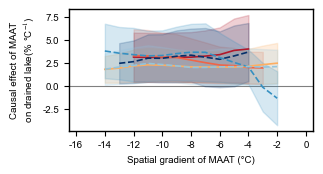


✅ 图像保存成功，尺寸：8cm × 5cm，路径：D:\Python39\Code-NG\results\F3c.svg


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
import os

# ===================== 全局统一配置  =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "legend.fontsize": 7,
    "svg.fonttype": "path"
}
rcParams.update(config)
df_hist_original = pd.read_csv(r'D:\Python39\Code-NG\data\ITE_Drainage_LSED_ERA.csv').copy()
output_dir = r"D:\Python39\Code-NG\results"
# ===================== 核心函数 =====================
def simple_smooth(data, window=3):
    """数据平滑"""
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# ===================== 分组数据处理函数 =====================
def process_group_data(df_group, bins):
    """处理单个分组：温度分箱→聚合→平滑→瞬时效应，并乘以100转为百分比数值"""
    # 温度分箱
    df_group['TAS_bin'] = pd.cut(df_group['ERA_TAS'], bins=bins, right=True, include_lowest=True)
    df_group['TAS_bin_label'] = df_group['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    df_group = df_group.dropna(subset=['TAS_bin_label']).copy()
    df_group['TAS_bin_label'] = df_group['TAS_bin_label'].astype(int)
    
    # 分箱聚合统计
    binned = df_group.groupby('TAS_bin_label', observed=True).agg(
        total_mean=('Total_ITE', 'mean'),    
        total_lower=('Total_lower', 'mean'),
        total_upper=('Total_upper', 'mean')
    ).reset_index().sort_values('TAS_bin_label')
    
    # 筛选有效温度区间
    binned_stats = binned[
        (binned['TAS_bin_label'] >= -16) &
        (binned['TAS_bin_label'] <= 0)
    ].sort_values('TAS_bin_label').reset_index(drop=True)
    
    # 数据平滑（瞬时因果效应）
    binned_stats['mean_smooth'] = simple_smooth(binned_stats['total_mean'], window=3)
    binned_stats['lower_smooth'] = simple_smooth(binned_stats['total_lower'], window=3)
    binned_stats['upper_smooth'] = simple_smooth(binned_stats['total_upper'], window=3)

    # 所有效应数值 ×100 转换为百分比数值
    for col in ['mean_smooth', 'lower_smooth', 'upper_smooth']:
        binned_stats[col] = binned_stats[col] * 100
    
    return binned_stats

# ===================== 1. 数据读取 =====================


total_original = len(df_hist_original)
print("="*60)
print("数据筛选阶段统计（样本量及占比）：")
print(f"1. 原始数据总量：{total_original:,} 条")

# ===================== 2. 基础筛选 =====================
df_hist = df_hist_original[(df_hist_original['ERA_TAS'] > -18)].copy()
total_after_basic_filter = len(df_hist)
basic_filter_ratio = (total_after_basic_filter / total_original) * 100
print(f"2. 基础筛选（ERA_TAS > -18）后：{total_after_basic_filter:,} 条 | 占原始数据比例：{basic_filter_ratio:.2f}%")

# ===================== 3. 显著性筛选 =====================
significant_filter = (
    ~((df_hist['Total_lower'] < 0) & (df_hist['Total_upper'] > 0)) 
)
df_hist = df_hist[significant_filter].copy()
total_after_significant_filter = len(df_hist)

significant_ratio_vs_basic = (total_after_significant_filter / total_after_basic_filter) * 100
significant_ratio_vs_original = (total_after_significant_filter / total_original) * 100
print(f"3. 显著性筛选后：{total_after_significant_filter:,} 条")
print(f"   - 占基础筛选数据比例：{significant_ratio_vs_basic:.2f}%")
print(f"   - 占原始数据比例：{significant_ratio_vs_original:.2f}%")
print("="*60)

if len(df_hist) == 0:
    raise ValueError("无显著性ITE数据（所有置信区间都包含0）")

# ===================== 6组分组逻辑 =====================
df_hist['ratio'] = (df_hist['Lake_density'] * 100)

conditions = [
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] > 5) & (df_hist['ICE'] == 1),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 3),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 2),
    (df_hist['ratio'] < 5) & (df_hist['ICE'] == 1),
]

choices = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]

df_hist['group'] = np.select(conditions, choices, default=np.nan)
df_hist = df_hist.dropna(subset=['group']).copy()

group_counts = df_hist['group'].value_counts().to_dict()
print(f"✅ 6组分组完成，有效数据量：{len(df_hist):,} 条")
print(f"📊 各组样本量统计：\n{df_hist['group'].value_counts()}")
print("="*60)

# ===================== 分组处理 =====================
bins = np.arange(-17, 1, 1)
group_order = [
    'Lake-rich & High ice content',
    'Lake-rich & Median ice content',
    'Lake-rich & Low ice content',
    'Lake-poor & High ice content',
    'Lake-poor & Median ice content',
    'Lake-poor & Low ice content',
]
group_results = {}

for group_name in group_order:
    if group_name in df_hist['group'].values:
        group_df = df_hist[df_hist['group'] == group_name].copy()
        group_results[group_name] = process_group_data(group_df, bins)
    else:
        print(f"⚠️ 分组 {group_name} 无数据，跳过")

# ===================== 样式配置 =====================
style_config = {
    'Lake-rich & High ice content':   {'color': '#b2182b', 'linestyle': '-'},
    'Lake-rich & Median ice content': {'color': '#ef6548', 'linestyle': '-'},
    'Lake-rich & Low ice content':    {'color': '#fdae61', 'linestyle': '-'},
    'Lake-poor & High ice content':   {'color': '#05306a', 'linestyle': '--'},
    'Lake-poor & Median ice content': {'color': '#3690c1', 'linestyle': '--'},
    'Lake-poor & Low ice content':    {'color': '#92c5de', 'linestyle': '--'}
}

# ===================== 绘图：尺寸 8cm × 5cm =====================
fig_width_cm = 8
fig_height_cm = 4
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()

# 循环绘制所有分组
for group_name, stats in group_results.items():
    style = style_config[group_name]
    color = style['color']
    linestyle = style['linestyle']
    
    # 绘制曲线与置信区间，不收集图例信息
    ax.plot(
        stats['TAS_bin_label'], stats['mean_smooth'],
        color=color, linewidth=1.2, linestyle=linestyle
    )
    ax.fill_between(
        stats['TAS_bin_label'], stats['lower_smooth'], stats['upper_smooth'],
        color=color, alpha=0.2
    )

# 坐标轴设置
ax.set_xlabel('Spatial gradient of MAAT (°C)')
ax.set_ylabel('Causal effect of MAAT\n on drained lake(% °C$^{-1}$)')
ax.set_xlim(-16.5, 0.5)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.axhline(y=0, color='black', linestyle='-', alpha=0.5, zorder=0, linewidth=0.8)

# 统一边框宽度
for spine in ax.spines.values():
    spine.set_linewidth(1)

# ===================== 输出路径  =====================

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F3c.svg")
plt.savefig(save_path, format="svg", bbox_inches='tight')
plt.show()
plt.close()

# ===================== 控制台输出 =====================
print(f"\n✅ 图像保存成功，尺寸：8cm × 5cm，路径：{save_path}")
print("="*60)

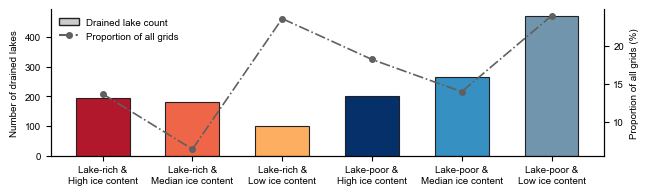

绘图完成，文件保存至：D:\Python39\Code-NG\results\F3d.svg
全局总网格数（未筛选）：83226
各组信息：
Lake-rich & High ice content | drained=195, all grids=11402, proportion=13.70%
Lake-rich & Median ice content | drained=181, all grids=5322, proportion=6.39%
Lake-rich & Low ice content | drained=100, all grids=19665, proportion=23.63%
Lake-poor & High ice content | drained=201, all grids=15181, proportion=18.24%
Lake-poor & Median ice content | drained=264, all grids=11634, proportion=13.98%
Lake-poor & Low ice content | drained=470, all grids=19973, proportion=24.00%

===== 全局总体统计 =====
全部网格总数: 83226
发生湖泊排水事件的网格总数: 1411
排水网格占全部网格比例: 1.70 %

===== 各组内部排水网格占本组网格比例（组内发生率） =====
Lake-rich & High ice content | drained=195, group total=11402, within-group drain ratio=1.71 %
Lake-rich & Median ice content | drained=181, group total=5322, within-group drain ratio=3.40 %
Lake-rich & Low ice content | drained=100, group total=19665, within-group drain ratio=0.51 %
Lake-poor & High ice content | drained=201, group total=1518

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ========== 全局字体设置 ==========
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 7
plt.rcParams["legend.fontsize"] = 7

f_path=r'D:\Python39\Code-NG\data\Data_all.csv'
output_dir = r"D:\Python39\Code-NG\results"
# 每组柱子对应颜色
group_color_map = {
    'Lake-rich &\nHigh ice content':   '#b2182b',
    'Lake-rich &\nMedian ice content': '#ef6548',
    'Lake-rich &\nLow ice content':    '#fdae61',
    'Lake-poor &\nHigh ice content':   '#05306a',
    'Lake-poor &\nMedian ice content': '#3690c1',
    'Lake-poor &\nLow ice content':    '#7295ae',
}
line_color = '#606060'  # 调浅折线颜色

# 1. 读取完整原始数据
df_raw = pd.read_csv(f_path, low_memory=False, encoding="utf-8-sig")
df_raw['ratio'] = (df_raw['mean_LSED'] / df_raw['Grid_Area'] * 100).values

# 全部网格总数（未做任何筛选，用来计算占比）
total_all_grids = len(df_raw)

# 2. 分组筛选条件
group_config = {
    'Lake-rich &\nHigh ice content': {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 3)},
    'Lake-rich &\nMedian ice content': {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 2)},
    'Lake-rich &\nLow ice content': {'filter': (df_raw['ratio'] > 5) & (df_raw['ICE'] == 1)},
    'Lake-poor &\nHigh ice content': {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 3)},
    'Lake-poor &\nMedian ice content': {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 2)},
    'Lake-poor &\nLow ice content': {'filter': (df_raw['ratio'] < 5) & (df_raw['ICE'] == 1)},
}
group_names = list(group_config.keys())

group_drain_count = []   
group_all_grid_count = [] 

for name in group_names:
    mask = group_config[name]['filter']
    dfg = df_raw[mask].copy()
    # 该分组所有网格数量
    n_all = len(dfg)
    # 该分组内排水湖泊数量
    n_drain = len(dfg[dfg["drainage_flag"] != 0])
    
    group_all_grid_count.append(n_all)
    group_drain_count.append(n_drain)

# 【重点】占比 = 本组全部网格 / 全局所有网格（未筛选）
group_percent = [n_all / total_all_grids * 100 for n_all in group_all_grid_count]

x_pos = np.arange(len(group_names))
bar_width = 0.6

# 3. 画布：单图
fig_width_cm = 16.5
fig_height_cm = 5
fig, ax = plt.subplots(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))

# 主坐标轴柱状图：每组drained lake数量
bars = ax.bar(
    x_pos, group_drain_count, width=bar_width,
    color=[group_color_map[name] for name in group_names],
    edgecolor="#222222", linewidth=0.8
)

# 副坐标轴折线：点虚线 linestyle='-.',颜色调浅
ax2 = ax.twinx()
ax2.plot(x_pos, group_percent, color=line_color, marker='o', linestyle='-.', markersize=4, linewidth=1.2)

# 坐标轴标签
ax.set_ylabel("Number of drained lakes", fontsize=7, color="black")
ax2.set_ylabel("Proportion of all grids (%)", fontsize=7, color="black")
# 双轴刻度文字全部改为黑色
ax.tick_params(axis='y', labelcolor="black")
ax2.tick_params(axis='y', labelcolor="black")

ax.set_xticks(x_pos)
ax.set_xticklabels(group_names, fontsize=7)

# 边框美化
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# ========== 图例修改 ==========
legend_elements = [
    Patch(facecolor="#cccccc", edgecolor="#222222", label="Drained lake count"),
    Line2D([], [], marker='o', color=line_color, linestyle='-.', markersize=4, label="Proportion of all grids")
]
ax.legend(handles=legend_elements, loc="upper left", frameon=False)

# 输出保存

os.makedirs(output_dir, exist_ok=True)
save_path = os.path.join(output_dir, "F3d.svg")

plt.tight_layout()
plt.savefig(save_path, format="svg", bbox_inches="tight")
plt.show()
plt.close()

print(f"绘图完成，文件保存至：{save_path}")
print(f"全局总网格数（未筛选）：{total_all_grids}")
print("各组信息：")
for name, nd, na, p in zip(group_names, group_drain_count, group_all_grid_count, group_percent):
    print(f"{name.replace(chr(10),' ')} | drained={nd}, all grids={na}, proportion={p:.2f}%")
    # ========= 全局排水网格总体统计 =========
# 全部网格中存在排水事件的样本
total_drain_grids = len(df_raw[df_raw["drainage_flag"] != 0])
total_all_grids = len(df_raw)
ratio_total_drain = total_drain_grids / total_all_grids * 100

print("\n===== 全局总体统计 =====")
print(f"全部网格总数: {total_all_grids}")
print(f"发生湖泊排水事件的网格总数: {total_drain_grids}")
print(f"排水网格占全部网格比例: {ratio_total_drain:.2f} %")

# ========= 每组内部【本组内排水网格 / 本组全部网格】的占比（组内发生率） =========
print("\n===== 各组内部排水网格占本组网格比例（组内发生率） =====")
for name, nd, na in zip(group_names, group_drain_count, group_all_grid_count):
    if na > 0:
        within_group_ratio = nd / na * 100
    else:
        within_group_ratio = 0.0
    print(f"{name.replace(chr(10),' ')} | drained={nd}, group total={na}, within-group drain ratio={within_group_ratio:.2f} %")

Data filtering statistics:
1. Raw data: 84,388 records
2. After basic filter (ERA_TAS > -18): 84,388 records | Ratio: 100.00%
✅ Disturbance-induced ice-rich permafrost pattern | Samples: 6,932
✅ Disturbance-induced ice-poor permafrost pattern | Samples: 8,002
✅ Overall ice-rich permafrost pattern | Samples: 20,293
✅ Overall ice-poor permafrost pattern | Samples: 16,728


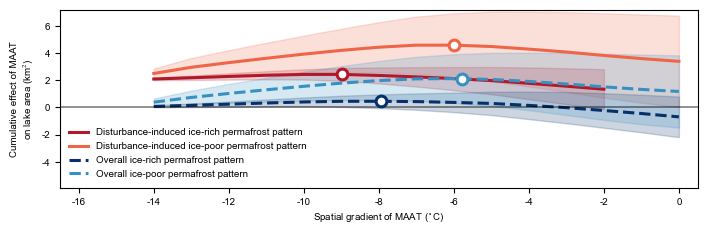

✅ Figure saved: D:\Python39\Code-NG\results\F4a.svg

========== Tipping Point & Zero-Crossing Summary ==========

Disturbance-induced ice-rich permafrost pattern:
  Tipping point: -8.98$^\circ$C
  Zero-crossing: Mean=-8.98$^\circ$C | Lower=-10.43$^\circ$C | Upper=-4.88$^\circ$C
  Confidence interval: [-10.43, -4.88]$^\circ$C

Disturbance-induced ice-poor permafrost pattern:
  Tipping point: -6.00$^\circ$C
  Zero-crossing: Mean=-6.00$^\circ$C | Lower=-8.25$^\circ$C | Upper=-4.04$^\circ$C
  Confidence interval: [-8.25, -4.04]$^\circ$C

Overall ice-rich permafrost pattern:
  Tipping point: -7.93$^\circ$C
  Zero-crossing: Mean=-7.93$^\circ$C | Lower=-9.85$^\circ$C | Upper=-3.73$^\circ$C
  Confidence interval: [-9.85, -3.73]$^\circ$C

Overall ice-poor permafrost pattern:
  Tipping point: -5.78$^\circ$C
  Zero-crossing: Mean=-5.78$^\circ$C | Lower=-7.90$^\circ$C | Upper=-3.66$^\circ$C
  Confidence interval: [-7.90, -3.66]$^\circ$C


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

# ===================== 全局可配置变量 =====================
file=r'D:\Python39\Code-NG\data\ITE_LSED_ERA.csv'
out_dir = r"D:\Python39\Code-NG\results"

ERA_TAS_COL = 'ERA_TAS'
GRID_AREA_COL = 'Grid_Area'
ICE_COL = 'ICE'

# 分组名称
GROUP1 = "Disturbance-induced ice-rich permafrost pattern"
GROUP2 = "Disturbance-induced ice-poor permafrost pattern"
GROUP3 = "Overall ice-rich permafrost pattern"
GROUP4 = "Overall ice-poor permafrost pattern"

# 颜色线型配置
GROUP_CONFIG = {
    GROUP1: {"color": '#b2182b', "linestyle": '-'},
    GROUP2: {"color": '#ef6548', "linestyle": '-'},
    GROUP3: {"color": '#05306a', "linestyle": '--'},
    GROUP4: {"color": '#3690c1', "linestyle": '--'}
}

# ===================== 字体配置 =====================
config = {
    "font.family": 'Arial',
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.unicode_minus": False,
    "mathtext.fontset": 'stix',
    "figure.dpi": 100,
    "savefig.dpi": 300
}
rcParams.update(config)

# ===================== 核心函数 =====================
def simple_smooth(data, window=3):
    return pd.Series(data).rolling(window=window, center=True, min_periods=1).mean().values

# 0轴交点检测
def get_cross_zero_universal(x_series, y_series, search_min=-16, search_max=0):
    df = pd.DataFrame({'x': x_series, 'y': y_series}).copy()
    df_search = df[(df['x'] >= search_min) & (df['x'] <= search_max)].sort_values('x').reset_index(drop=True)
    cross_temp = None
    if len(df_search) >= 2:
        for i in range(len(df_search)-1):
            x1, y1 = df_search.iloc[i]['x'], df_search.iloc[i]['y']
            x2, y2 = df_search.iloc[i+1]['x'], df_search.iloc[i+1]['y']
            if np.sign(y1) != np.sign(y2):
                k = (y2 - y1) / (x2 - x1)
                cross_temp = x1 - (y1 / k)
                break
    return cross_temp

# 计算正确拐点：CATE曲线由负变正的0轴交点
def calculate_tipping_point(binned_df):
    tipping_point = None
    tipping_range = binned_df[
        (binned_df['TAS_bin_label'] >= -16) &
        (binned_df['TAS_bin_label'] < 0)
    ].sort_values('TAS_bin_label', ascending=False).reset_index(drop=True)
    
    if len(tipping_range) >= 2:
        for i in range(len(tipping_range) - 1):
            x1, y1 = tipping_range.iloc[i]['TAS_bin_label'], tipping_range.iloc[i]['total_mean_smooth']
            x2, y2 = tipping_range.iloc[i+1]['TAS_bin_label'], tipping_range.iloc[i+1]['total_mean_smooth']
            if y1 < 0 and y2 > 0:
                k = (y2 - y1) / (x2 - x1)
                tipping_x = x1 - (y1 / k)
                tipping_point = (tipping_x, 0)
                break
    return tipping_point

# ===================== 累积曲线处理函数 =====================
def process_group_data(df_group, bins):
    """处理单个分组：温度分箱→聚合→平滑→计算累积积分曲线"""
    df_group['TAS_bin'] = pd.cut(df_group[ERA_TAS_COL], bins=bins, right=True, include_lowest=True)
    df_group['TAS_bin_label'] = df_group['TAS_bin'].apply(lambda x: x.right if pd.notna(x) else np.nan)
    df_group = df_group.dropna(subset=['TAS_bin_label']).copy()
    df_group['TAS_bin_label'] = df_group['TAS_bin_label'].astype(int)
    
    binned = df_group.groupby('TAS_bin_label', observed=True).agg(
        total_mean=('Total_ITE', 'mean'),    
        total_lower=('Total_lower', 'mean'),
        total_upper=('Total_upper', 'mean')
    ).reset_index().sort_values('TAS_bin_label')
    
    binned_stats = binned[
        (binned['TAS_bin_label'] >= -16) &
        (binned['TAS_bin_label'] <= 0)
    ].sort_values('TAS_bin_label').reset_index(drop=True)
    
    # CATE平滑（用于计算正确拐点）
    binned_stats['total_mean_smooth'] = simple_smooth(binned_stats['total_mean'], window=3)
    binned_stats['total_lower_smooth'] = simple_smooth(binned_stats['total_lower'], window=3)
    binned_stats['total_upper_smooth'] = simple_smooth(binned_stats['total_upper'], window=3)
    
    # 累积曲线平滑（用于绘图）
    binned_stats['mean_smooth'] = binned_stats['total_mean_smooth']
    binned_stats['lower_smooth'] = binned_stats['total_lower_smooth']
    binned_stats['upper_smooth'] = binned_stats['total_upper_smooth']
    
    # 累积和
    binned_stats['cumsum'] = binned_stats['mean_smooth'].cumsum()
    binned_stats['cumsum_lower'] = binned_stats['lower_smooth'].cumsum()
    binned_stats['cumsum_upper'] = binned_stats['upper_smooth'].cumsum()
    
    return binned_stats

# ===================== 数据读取与筛选 =====================
df_hist_original = pd.read_csv(file).copy()
total_original = len(df_hist_original)
print("="*60)
print("Data filtering statistics:")
print(f"1. Raw data: {total_original:,} records")

df_hist = df_hist_original[(df_hist_original[ERA_TAS_COL] > -18)].copy()
total_after_basic_filter = len(df_hist)
basic_filter_ratio = (total_after_basic_filter / total_original) * 100
print(f"2. After basic filter ({ERA_TAS_COL} > -18): {total_after_basic_filter:,} records | Ratio: {basic_filter_ratio:.2f}%")

significant_filter = (~((df_hist['Total_lower'] < 0) & (df_hist['Total_upper'] > 0)))
df_hist = df_hist[significant_filter].copy()
total_after_significant_filter = len(df_hist)

if len(df_hist) == 0:
    raise ValueError("No significant ITE data")

df_hist['ratio'] = (df_hist['Lake_density'] * 100)

# 分组定义
group_definitions = [
    {"name": GROUP1, "filter": (df_hist['ratio'] > 5) & (df_hist[ICE_COL].isin([3,2]))},
    {"name": GROUP2, "filter": (df_hist['ratio'] > 5) & (df_hist[ICE_COL].isin([1]))},
    {"name": GROUP3, "filter": (df_hist[ICE_COL].isin([3,2]))},
    {"name": GROUP4, "filter": (df_hist[ICE_COL].isin([1]))},
]

bins = np.arange(-17, 1, 1)

# ===================== 处理分组 + 计算 =====================
group_results = {}
group_tipping = {}
group_cross = {}

for g in group_definitions:
    group_name = g["name"]
    group_filter = g["filter"]
    group_df = df_hist[group_filter].copy()
    print(f"✅ {group_name} | Samples: {len(group_df):,}")
    
    if len(group_df) > 0:
        stats = process_group_data(group_df, bins)
        group_results[group_name] = stats
        group_tipping[group_name] = calculate_tipping_point(stats)
        mean_cross = get_cross_zero_universal(stats['TAS_bin_label'], stats['total_mean_smooth'])
        upper_cross = get_cross_zero_universal(stats['TAS_bin_label'], stats['total_upper_smooth'])
        lower_cross = get_cross_zero_universal(stats['TAS_bin_label'], stats['total_lower_smooth'])
        group_cross[group_name] = {'mean': mean_cross, 'upper': upper_cross, 'lower': lower_cross}

print("="*60)

# ===================== 累积曲线偏移 =====================
for group_name in group_results:
    if 'Disturbance' in group_name:
        group_results[group_name]['cumsum'] += 2
        group_results[group_name]['cumsum_lower'] += 2
        group_results[group_name]['cumsum_upper'] += 2

# ===================== 绘图 =====================
fig_width_cm = 18
fig_height_cm = 6
plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))
ax = plt.gca()

for g in group_definitions:
    group_name = g["name"]
    if group_name not in group_results:
        continue
        
    style = GROUP_CONFIG[group_name]
    color = style["color"]
    linestyle = style["linestyle"]
    stats = group_results[group_name]
    x = stats['TAS_bin_label']
    y = stats['cumsum']
    
    # 线条粗细适配小图
    ax.plot(x, y, linewidth=2.2, color=color, linestyle=linestyle, label=group_name)
    ax.fill_between(x, stats['cumsum_lower'], stats['cumsum_upper'], color=color, alpha=0.2)
    
    # 拐点标记
    tipping_point = group_tipping[group_name]
    if tipping_point:
        tip_x = tipping_point[0]
        tip_y = np.interp(tip_x, stats['TAS_bin_label'], stats['cumsum'])
        ax.scatter(
            tip_x, tip_y,
            s=60, edgecolor=color, facecolor='white', linewidth=2.2, zorder=5
        )

# 坐标轴设置
ax.set_xlabel('Spatial gradient of MAAT ($^\circ$C)')
ax.set_ylabel('Cumulative effect of MAAT\non lake area (km$^{2}$)')
ax.set_xlim(-16.5, 0.5)
ax.set_ylim(-5.9, 7.2)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_major_locator(MultipleLocator(2))
ax.axhline(y=0, color='black', linestyle='-', alpha=0.5, linewidth=1.2)
ax.legend(loc='best', frameon=False)

plt.tight_layout()

# 输出路径
import os

os.makedirs(out_dir, exist_ok=True)
save_path = os.path.join(out_dir, "F4a.svg")
plt.savefig(save_path, format="svg", bbox_inches='tight')
plt.show()
plt.close()
print(f"✅ Figure saved: {save_path}")

# ===================== 拐点汇总输出 =====================
print("\n========== Tipping Point & Zero-Crossing Summary ==========")
for g in group_definitions:
    group_name = g["name"]
    if group_name not in group_results:
        continue
    tp = group_tipping[group_name]
    cross = group_cross[group_name]
    
    print(f"\n{group_name}:")
    if tp:
        print(f"  Tipping point: {tp[0]:.2f}$^\circ$C")
    else:
        print(f"  Tipping point: Not detected")
    
    mean_str = f"{cross['mean']:.2f}" if cross['mean'] else "Not detected"
    lower_str = f"{cross['lower']:.2f}" if cross['lower'] else "Not detected"
    upper_str = f"{cross['upper']:.2f}" if cross['upper'] else "Not detected"
    print(f"  Zero-crossing: Mean={mean_str}$^\circ$C | Lower={lower_str}$^\circ$C | Upper={upper_str}$^\circ$C")
    
    if cross['lower'] and cross['upper']:
        print(f"  Confidence interval: [{min(cross['lower'],cross['upper']):.2f}, {max(cross['lower'],cross['upper']):.2f}]$^\circ$C")